# 1.06. Опасность малой мощности. Ошибки S и M типов

**План занятия**

1. Почему одной мощности недостаточно: классическая постановка A/B-теста и её слепые зоны.
2. Ошибки Type S и Type M: определения, точные формулы, интерактивная демонстрация.
3. Design Analysis и почему нельзя подставлять наблюдённый эффект в расчёт мощности.
4. Симуляции: влияние размера выборки и величины эффекта, фильтр значимости.
5. Как это применять в A/B-тесте: что происходит, если истинный эффект меньше MDE.
6. Примеры из статьи Gelman & Carlin.
7. Что делать на практике: репликация, сжатие оценок, планирование.


## Библиотеки и общие функции


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from ipywidgets import FloatLogSlider, FloatSlider, interact
from scipy import stats

pd.set_option('display.width', 1000)
pd.set_option('display.max_columns', 100)

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

BLUE, RED, GREEN, ORANGE, GRAY = '#4C72B0', '#C44E52', '#55A868', '#DD8452', '#7F7F7F'

BASE_CONFIG = {
    "p_control": 0.10,
    "p_test_main": 0.102,  # истинный uplift = +0.2 п.п.
    "alpha": 0.05,
    "n_sim_main": 20_000,
    "n_sim_hist": 50_000,
    "base_seed": 42,
}


def format_n_ru(n: float) -> str:
    """Форматирует число с пробелом как разделителем тысяч."""
    return f"{int(n):_}".replace("_", " ")


def two_proportion_z_test_from_counts(x_c: np.ndarray, n_c: int, x_t: np.ndarray, n_t: int) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Двусторонний z-тест для двух долей: возвращает оценку эффекта, z-статистику и p-value."""
    p_c_hat = x_c / n_c
    p_t_hat = x_t / n_t
    effect_hat = p_t_hat - p_c_hat

    p_pool = (x_c + x_t) / (n_c + n_t)
    se0 = np.sqrt(p_pool * (1 - p_pool) * (1 / n_c + 1 / n_t))

    z_stat = effect_hat / se0
    p_value = 2 * stats.norm.sf(np.abs(z_stat))
    return effect_hat, z_stat, p_value


def simulate_ab_binary(p_control: float, p_test: float, n_per_group: int, n_sim: int = 20_000,
                       alpha: float = 0.05, seed: int = 42) -> dict:
    """Симулирует A/B-тест бинарной метрики и считает мощность, Type S и Type M."""
    rng = np.random.default_rng(seed)
    x_c = rng.binomial(n=n_per_group, p=p_control, size=n_sim)
    x_t = rng.binomial(n=n_per_group, p=p_test, size=n_sim)
    effect_hat, z_stat, p_value = two_proportion_z_test_from_counts(x_c, n_per_group, x_t, n_per_group)

    significant = p_value < alpha
    true_effect = p_test - p_control
    type_s, type_m = np.nan, np.nan
    if not np.isclose(true_effect, 0) and significant.any():
        type_s = np.mean(np.sign(effect_hat[significant]) != np.sign(true_effect))
        type_m = np.mean(np.abs(effect_hat[significant])) / np.abs(true_effect)

    return {
        "true_effect": true_effect,
        "effect_hat": effect_hat,
        "significant": significant,
        "power": np.mean(significant),
        "type_s": type_s,
        "type_m": type_m,
        "significant_count": int(significant.sum()),
    }


def retrodesign(true_effect: float | np.ndarray, se: float | np.ndarray, alpha: float = 0.05) -> dict[str, float | np.ndarray]:
    """Считает мощность, Type S и Type M по точным формулам для нормально распределённой оценки."""
    z = stats.norm.ppf(1 - alpha / 2)
    lam = np.abs(true_effect) / se
    p_right = stats.norm.sf(z - lam)
    p_wrong = stats.norm.cdf(-z - lam)
    power = p_right + p_wrong
    with np.errstate(divide='ignore', invalid='ignore'):
        type_m = (lam * (p_right - p_wrong) + stats.norm.pdf(z - lam) + stats.norm.pdf(z + lam)) / (lam * power)
    return {"power": power, "type_s": p_wrong / power, "type_m": type_m, "p_right": p_right, "p_wrong": p_wrong}


def se_of_difference(p_control: float, p_test: float, n_per_group: float) -> float | np.ndarray:
    """Считает стандартную ошибку разницы двух долей."""
    return np.sqrt((p_control * (1 - p_control) + p_test * (1 - p_test)) / n_per_group)


def required_n(p_control: float, p_test: float, alpha: float = 0.05, power: float = 0.8) -> int:
    """Считает размер одной группы для заданной мощности."""
    z_sum = stats.norm.ppf(1 - alpha / 2) + stats.norm.ppf(power)
    variance = p_control * (1 - p_control) + p_test * (1 - p_test)
    return int(np.ceil(z_sum ** 2 * variance / (p_test - p_control) ** 2))


def plot_sampling_distribution(ax: plt.Axes, true_effect: float, se: float, alpha: float = 0.05) -> None:
    """Рисует распределение оценки эффекта и закрашивает зоны значимости."""
    design = retrodesign(true_effect, se, alpha)
    z = stats.norm.ppf(1 - alpha / 2)
    limit = max(5 * se, abs(true_effect) + 4 * se)
    grid = np.linspace(-limit, limit, 1_000)
    density = stats.norm.pdf(grid, true_effect, se)

    ax.plot(grid, density, color=GRAY)
    ax.fill_between(grid, density, where=grid > z * se, color=GREEN, alpha=0.7,
                    label=f"Значимо, верный знак: {design['p_right']:.1%}")
    ax.fill_between(grid, density, where=grid < -z * se, color=RED, alpha=0.7,
                    label=f"Значимо, неверный знак: {design['p_wrong']:.1%}")
    ax.axvline(true_effect, color='black', linestyle='--', label='Истинный эффект')
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x * 100:.1f}'))
    ax.set_xlabel('Оценка эффекта, п.п.')
    ax.set_yticks([])
    ax.set_ylim(0, density.max() * 1.45)
    ax.set_title(f"Мощность {design['power']:.1%}, Type S {design['type_s']:.1%}, Type M {design['type_m']:.1f}")
    ax.legend(loc='upper right', fontsize=10)


## Почему одной мощности недостаточно

В классическом подходе к планированию эксперимента обычно обсуждают ошибки I и II рода, уровень значимости $\alpha$, мощность теста $1-\beta$ и MDE. Этого достаточно, чтобы ответить на вопрос: **«С какой вероятностью мы обнаружим эффект заданного размера?»**

Но для практики A/B-тестов этого часто мало. Даже если результат статистически значим, остаются два важных вопроса:

1. **Не перепутали ли мы направление эффекта?** Например, решили, что новая фича улучшает метрику, хотя в реальности она её ухудшает.
2. **Не завышаем ли мы размер эффекта?** Например, увидели uplift $+1.2\text{ п.п.}$, а реальный эффект ближе к $+0.3\text{ п.п.}$

Для ответа на эти вопросы [Andrew Gelman и John Carlin](https://doi.org/10.1177/1745691614551642) предложили смотреть не только на перечисленные параметры, но и на:

- **Type S error (Sign)** — вероятность ошибиться в знаке эффекта;
- **Type M error (Magnitude)** — насколько значимый результат в среднем завышает истинный эффект.

> **Главный тезис.** Проблема низкой мощности не только в том, что мы можем не заметить реальный эффект. Среди «победивших» значимых результатов будут непропорционально часто встречаться слишком большие и иногда даже неверные по знаку оценки.

Поэтому хороший анализ A/B-теста отвечает не только на вопрос «обнаружим ли мы эффект?», но и на вопросы «насколько можно доверять знаку эффекта?» и «насколько значимый результат может преувеличивать реальный uplift?».

**Почему эта проблема важна.** Интерес к Type S и Type M возник не на пустом месте. В психологии, медицине и других областях накопилось много значимых результатов, которые плохо воспроизводились. В известном [Reproducibility Project](https://doi.org/10.1126/science.aac4716) повторили 100 исследований по психологии: в оригинальных работах значимые результаты наблюдались почти всегда, а в репликациях — примерно в трети случаев. Это не означает, что все исходные результаты были ложными, но показывает, что **сам факт статистической значимости не гарантирует надёжность оценки по знаку и масштабу**.

Значимый эффект может:

- иметь неверный знак;
- быть сильно завышен по модулю;
- не воспроизвестись в следующем эксперименте.


## 1. Классическая постановка A/B-теста

Пусть мы сравниваем контрольную и тестовую версии продукта. Обозначим истинный эффект через $\theta$:

- $\theta > 0$ — тест улучшает метрику;
- $\theta = 0$ — эффекта нет;
- $\theta < 0$ — тест ухудшает метрику.

Обычно проверяется гипотеза

$$
H_0:\theta = 0
\qquad \text{против} \qquad
H_1:\theta \neq 0
$$

**Ошибка I рода** — отвергаем $H_0$, хотя эффекта нет. Это ложноположительный результат: решили, что фича работает, хотя реального эффекта нет.

$$
\alpha = P(\text{отвергли } H_0 \mid H_0 \text{ верна})
$$

**Ошибка II рода** — не отвергаем $H_0$, хотя реальный эффект есть. Это ложноотрицательный результат: мы пропустили полезную фичу.

$$
\beta = P(\text{не отвергли } H_0 \mid H_1 \text{ верна})
$$

**Мощность** — вероятность обнаружить эффект, если он действительно существует.

$$
1 - \beta = P(\text{отвергли } H_0 \mid H_1 \text{ верна})
$$

Анализ мощности (power analysis) полезен, но недостаточен. Он отвечает на вопрос «с какой вероятностью эксперимент обнаружит эффект?», но **не отвечает** на два практических вопроса:

1. Если результат значим, **верно ли определено направление эффекта**?
2. Если результат значим, **насколько оценка близка к истинному эффекту**?

Здесь и появляются ошибки Type S и Type M.


## 2. Ошибки Type S и Type M

Пусть $\hat{\theta}$ — оценка эффекта по данным, а $\theta$ — истинный эффект. Результат считается значимым по правилу

$$
|Z| > z_{1-\alpha/2}, \qquad Z = \frac{\hat{\theta}}{SE}
$$


### 2.1. Type S error (Sign)

**Type S error** — вероятность того, что при значимом результате знак оценки окажется неверным:

$$
\text{Type S} =
P\bigl(\operatorname{sign}(\hat{\theta}) \neq \operatorname{sign}(\theta)\mid \text{значимо}\bigr)
$$

Представим, что истинный эффект равен $\theta = +0.2 \text{ п.п.}$, то есть фича немного **улучшает** метрику. Но в одном шумном эксперименте мы получили значимую оценку $\hat{\theta} = -0.4 \text{ п.п.}$ Команда делает вывод, что фича **вредит**, и отключает её, хотя на самом деле всё наоборот.

Это не просто неточная оценка величины. Мы **перепутали само направление воздействия**.


### 2.2. Type M error (Magnitude)

**Type M error** — ожидаемое завышение величины эффекта среди значимых результатов. В статье её называют также exaggeration ratio (коэффициент преувеличения):

$$
\text{Type M} =
\frac{
E\bigl(|\hat{\theta}| \mid \text{значимо}\bigr)
}{
|\theta|
}
$$

Если истинный эффект $\theta = 0.2$, а среди значимых результатов средний модуль оценки равен $0.6$, то $\text{Type M} = 0.6 / 0.2 = 3$: **значимые результаты в среднем преувеличивают истинный эффект в 3 раза**.

Обратите внимание, что Type M — не вероятность, а отношение: оно всегда больше 1. В него входят и оценки с неверным знаком, потому что берётся модуль. Обе величины определены только при $\theta \neq 0$: если эффекта нет, то значимый результат — просто ошибка I рода, и завышать нечего.


### 2.3. Почему эти ошибки особенно важны в A/B-тестах

Ошибку II рода в продуктовой аналитике понимают хорошо: «жаль, мы не увидели полезный эффект». Но не менее опасны ситуации, где одновременно:

- тест маломощный;
- уровень шума в метрике высокий;
- реальный эффект мал по сравнению с дисперсией данных.

Тогда возникает следствие:

> значимыми чаще оказываются те реализации эксперимента, где наблюдённый эффект случайно получился особенно большим по модулю.

Команда может раскатить фичу на всех пользователей, закладывая в бизнес-оценку слишком большой uplift, и:

- ожидать эффект, который потом не воспроизведётся;
- в совсем плохом сценарии принять решение в неправильную сторону.


### 2.4. Как посчитать

Для нормально распределённой несмещённой оценки всё определяется одним числом — отношением эффекта к стандартной ошибке $\lambda = |\theta| / SE$. Обозначим $z = z_{1-\alpha/2}$, а $\Phi$ и $\varphi$ — функция распределения и плотность стандартного нормального закона. Тогда

$$
P_{+} = 1 - \Phi(z - \lambda), \qquad P_{-} = \Phi(-z - \lambda), \qquad \text{Мощность} = P_{+} + P_{-}
$$

$$
\text{Type S} = \frac{P_{-}}{P_{+} + P_{-}}, \qquad
\text{Type M} = \frac{\lambda (P_{+} - P_{-}) + \varphi(z - \lambda) + \varphi(z + \lambda)}{\lambda (P_{+} + P_{-})}
$$

Здесь $P_{+}$ и $P_{-}$ — вероятности значимого результата с верным и неверным знаком. Формулы для Type M в такой форме приведены у [Lu, Qiu, Deng](https://doi.org/10.1111/bmsp.12132). В статье Gelman & Carlin её считают симуляцией. В функции `retrodesign` выше реализованы эти формулы.

Есть и простая нижняя граница. Значимая оценка не может быть меньше $z \cdot SE$ по модулю, поэтому

$$
\text{Type M} \ge \frac{z \cdot SE}{|\theta|}
$$

**Какая бы ни была выборка, порог значимости сам задаёт минимальное завышение.** Посмотрим на это на примере конверсии 10% и истинного uplift +0.2 п.п.: слева слабый дизайн, справа мощный. Зелёным закрашены значимые результаты с верным знаком, красным — с неверным.


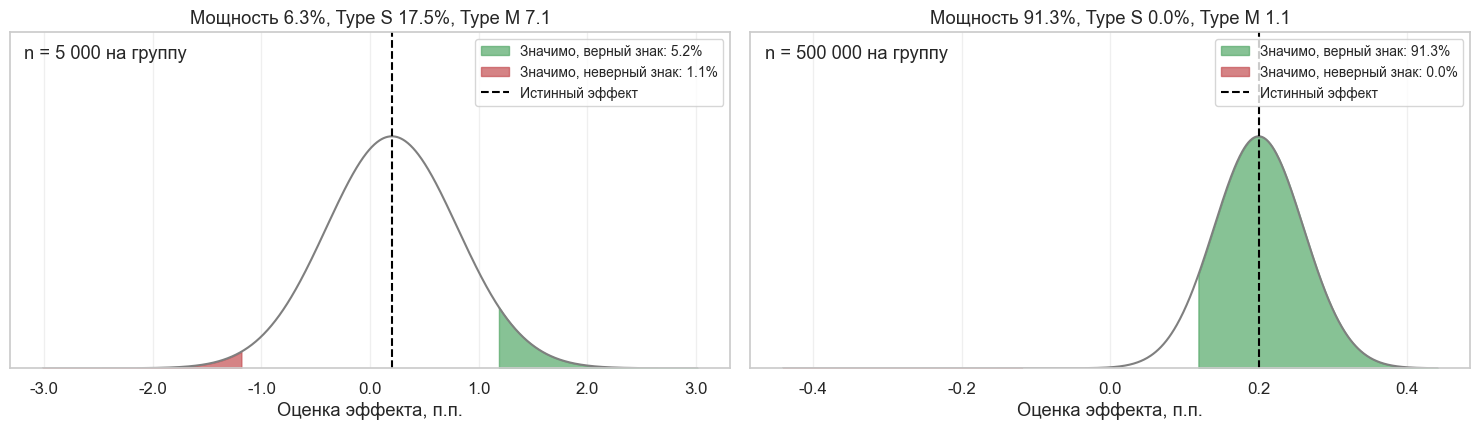

In [2]:
p_control = BASE_CONFIG["p_control"]
p_test = BASE_CONFIG["p_test_main"]
true_effect = p_test - p_control

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, n in zip(axes, (5_000, 500_000)):
    plot_sampling_distribution(ax, true_effect, se_of_difference(p_control, p_test, n))
    ax.text(0.02, 0.92, f'n = {format_n_ru(n)} на группу', transform=ax.transAxes)
plt.tight_layout()
plt.show()


**Попробуйте сами.** Эта ячейка интерактивная: запустите её в Colab или Jupyter и подвигайте ползунки. Найдите размер выборки, при котором красная зона исчезает, а затем — при котором Type M опускается ниже 1.5.


In [3]:
def design_demo(uplift_pp: float = 0.2, n_per_group: float = 5_000, base_rate: float = 0.10) -> None:
    """Показывает распределение оценки эффекта и design analysis для выбранного дизайна."""
    effect = uplift_pp / 100
    fig, ax = plt.subplots(figsize=(11, 4.5))
    plot_sampling_distribution(ax, effect, se_of_difference(base_rate, base_rate + effect, n_per_group))
    plt.tight_layout()
    plt.show()


interact(design_demo,
         uplift_pp=FloatSlider(value=0.2, min=0.05, max=2, step=0.05, description='Uplift, п.п.'),
         n_per_group=FloatLogSlider(value=5_000, base=10, min=3, max=6.5, step=0.1, description='n на группу'),
         base_rate=FloatSlider(value=0.10, min=0.01, max=0.5, step=0.01, description='Конверсия'));


## 3. Почему одного Power Analysis недостаточно. Design Analysis

### 3.1. Power Analysis и Design Analysis

Обычный Power Analysis устроен так:

1. Задаём $\alpha$.
2. Фиксируем желаемую мощность, например 80%.
3. Задаём минимальный интересующий эффект (MDE).
4. Считаем нужный размер выборки.

Это полезно, но фокус здесь почти исключительно на вопросе «получим ли мы значимость?». Gelman и Carlin показывают, что в шумных и маломощных исследованиях **значимый результат сам по себе может вводить в заблуждение**, и предлагают более широкую рамку — **Design Analysis**:

1. Задать правдоподобный **истинный эффект** $\theta$ на основе внешней информации.
2. Задать стандартную ошибку $SE$ оценки эффекта.
3. Рассмотреть, что дало бы гипотетическое повторение такого эксперимента много раз.

После этого оцениваются:

- **мощность** — как часто результат станет значимым;
- **Type S** — как часто среди значимых результатов знак будет ошибочным;
- **Type M** — насколько сильно значимые результаты завышают эффект.

Такой анализ лучше делать до запуска, но он полезен и после, если эффект взят не из самого теста.


### 3.2. Почему нужен правдоподобный эффект, а не наблюдённый

Нельзя брать **наблюдённую оценку из текущего эксперимента** и подставлять её как истинный эффект в расчёт мощности задним числом.

Если результат прошёл фильтр значимости, наблюдённый эффект часто **смещён вверх по модулю**. Например, команда получила uplift $\hat{\theta} = 1.2 \text{ п.п.}$, подставила эти же 1.2 п.п. в формулу и получила мощность 95%. Кажется, что эксперимент был очень надёжным.

Но здесь логическая ошибка:

> Результат мог стать значимым именно потому, что случайно оказался большим. Подставлять его назад в расчёт мощности нельзя: это эффект после фильтра значимости, а не независимая оценка истинного сигнала.

Такая **наблюдаемая мощность** вообще не содержит новой информации. Если подставить наблюдённый эффект, то $\lambda = |Z|$, и она становится взаимно однозначной функцией p-value ([Hoenig, Heisey, 2001](https://doi.org/10.1198/000313001300339897)):


In [4]:
p_values = np.array([0.20, 0.10, 0.05, 0.01, 0.001])
observed_z = stats.norm.isf(p_values / 2)
observed_power = retrodesign(observed_z, 1.0)["power"]

print(pd.DataFrame({'p-value': p_values, 'Наблюдаемая мощность': observed_power.round(3)}).to_string(index=False))


 p-value  Наблюдаемая мощность
   0.200                 0.249
   0.100                 0.376
   0.050                 0.500
   0.010                 0.731
   0.001                 0.908


Любой тест с p-value около 0.05 покажет наблюдаемую мощность около 50%, что бы ни происходило на самом деле. Это то же p-value, записанное в другой шкале. Gelman и Carlin отмечают и обратную сторону: чем слабее дизайн, тем больше значимая оценка, а значит, тем лучше такой тест выглядит при расчёте задним числом.

Поэтому для Design Analysis лучше опираться на:

- внешние исследования;
- историю похожих экспериментов;
- доменную экспертизу;
- диапазон правдоподобных эффектов, а не одно число.

История тоже может быть завышена, если в неё попадали в основном значимые результаты.


## 4. Симуляции

Проверим формулы и посмотрим, что они означают на практике.

### Симуляция №1: как размер выборки влияет на мощность, Type S и Type M

> Что произойдёт с качеством выводов, если увеличивать размер выборки?

Рассмотрим A/B-тест конверсии: $p_C = 0.10$, $p_T = 0.102$. Истинный эффект $\theta = 0.002$, то есть uplift **+0.2 п.п.** Размер выборки на группу меняем от 2 000 до 1 000 000.

Для каждого $n$:

1. Много раз генерируем контроль и тест.
2. Считаем наблюдённый эффект $\hat{\theta}$.
3. Считаем статистику и p-value.
4. Отмечаем, значим ли результат.
5. Считаем мощность, а среди значимых — долю неверных знаков (Type S) и среднее завышение (Type M).

Ожидаемая картина: мощность растёт, Type M снижается к 1, а Type S снижается ещё быстрее и заметен только в очень слабых дизайнах.


In [5]:
p_control = BASE_CONFIG["p_control"]
p_test = BASE_CONFIG["p_test_main"]
alpha = BASE_CONFIG["alpha"]
n_sim = BASE_CONFIG["n_sim_main"]

sample_sizes = [2_000, 5_000, 10_000, 20_000, 50_000, 100_000, 250_000, 500_000, 750_000, 1_000_000]

results_sim1 = []
for idx, n in enumerate(sample_sizes):
    sim = simulate_ab_binary(p_control, p_test, n, n_sim, alpha, seed=BASE_CONFIG["base_seed"] + 1000 + idx)
    theory = retrodesign(sim["true_effect"], se_of_difference(p_control, p_test, n), alpha)
    results_sim1.append({
        "n на группу": n,
        "power": sim["power"],
        "type_s": sim["type_s"],
        "type_m": sim["type_m"],
        "power, формула": theory["power"],
        "type_s, формула": theory["type_s"],
        "type_m, формула": theory["type_m"],
        "значимых": sim["significant_count"],
    })

df_sim1 = pd.DataFrame(results_sim1)
print(df_sim1.round(3).to_string(index=False))


 n на группу  power  type_s  type_m  power, формула  type_s, формула  type_m, формула  значимых
        2000  0.054   0.264  11.126           0.055            0.273           11.198      1073
        5000  0.063   0.177   7.130           0.063            0.175            7.131      1254
       10000  0.074   0.098   5.081           0.076            0.100            5.090      1471
       20000  0.103   0.044   3.654           0.102            0.043            3.652      2056
       50000  0.185   0.005   2.380           0.183            0.007            2.384      3703
      100000  0.325   0.001   1.753           0.317            0.001            1.757      6491
      250000  0.647   0.000   1.243           0.651            0.000            1.243     12947
      500000  0.915   0.000   1.051           0.913            0.000            1.052     18295
      750000  0.982   0.000   1.011           0.982            0.000            1.011     19648
     1000000  0.996   0.000   1.003     

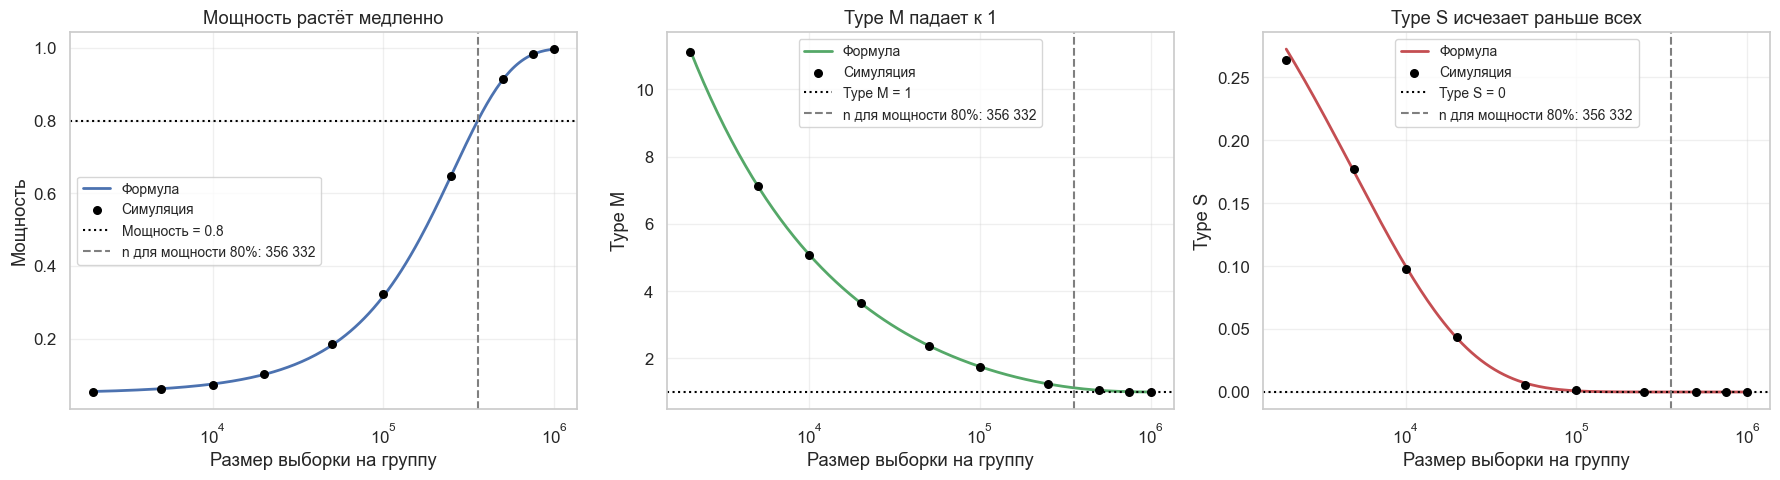

In [6]:
n_needed = required_n(p_control, p_test, alpha)
grid_n = np.geomspace(sample_sizes[0], sample_sizes[-1], 200)
theory_curve = retrodesign(p_test - p_control, se_of_difference(p_control, p_test, grid_n), alpha)

panels = (
    ('power', 'Мощность растёт медленно', 'Мощность', BLUE, 0.8, 'Мощность = 0.8'),
    ('type_m', 'Type M падает к 1', 'Type M', GREEN, 1.0, 'Type M = 1'),
    ('type_s', 'Type S исчезает раньше всех', 'Type S', RED, 0.0, 'Type S = 0'),
)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (key, title, ylabel, color, level, level_label) in zip(axes, panels):
    ax.plot(grid_n, theory_curve[key], color=color, linewidth=2, label='Формула')
    ax.scatter(df_sim1["n на группу"], df_sim1[key], color='black', zorder=3, s=30, label='Симуляция')
    ax.axhline(level, linestyle=':', color='black', label=level_label)
    ax.axvline(n_needed, linestyle='--', color=GRAY, label=f'n для мощности 80%: {format_n_ru(n_needed)}')
    ax.set_xscale('log')
    ax.set_title(title)
    ax.set_xlabel('Размер выборки на группу')
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=10)
plt.tight_layout()
plt.show()


Симуляция совпала с формулами, а разных эффектов от увеличения выборки здесь три:

* **Мощность** растёт монотонно, но медленно: при $n = 100\,000$ на группу она равна лишь 0.32. Эффект +0.2 п.п. очень мал, и для мощности 80% нужно около 356 332 пользователей на группу.
* **Type M** падает: при $n = 2\,000$ значимые результаты завышают истинный эффект в 11 раз, при $n = 50\,000$ — уже в 2.4 раза. Команда, получившая значимый результат на маленькой выборке, рискует заложить в бизнес-оценку эффект, который в реальности в несколько раз меньше.
* **Type S** при $n = 2\,000$ равен 0.26, то есть примерно каждый четвёртый значимый результат имеет неверный знак. При $n = 50\,000$ он падает до 0.005 и становится пренебрежимо малым.

При низкой мощности Type M близок к нижней границе $z \cdot SE / |\theta|$ и убывает как $1 / \sqrt{n}$: чтобы уменьшить завышение вдвое, выборку нужно увеличить примерно вчетверо. Значит, быстрого выигрыша нет, но и «почти достаточная» выборка не спасает: завышение исчезает только при мощности заметно выше 50%.


### Симуляция №2: как величина истинного эффекта влияет на качество вывода

> Что будет, если реальный эффект очень маленький, а тест остаётся тем же?

Фиксируем $n = 10\,000$ на группу и перебираем истинный uplift из набора $\{0, 0.0005, 0.001, 0.002, 0.005, 0.01\}$. Ожидаем:

* **Мощность** растёт с эффектом.
* **Type M** особенно велик у маленьких эффектов: значимыми становятся в основном экстремальные реализации.
* **Type S** опасен в зоне очень маленьких эффектов: шум может перевернуть знак.


In [7]:
n_per_group = 10_000
true_effects = [0.0, 0.0005, 0.001, 0.002, 0.005, 0.01]  # 0.002 = +0.2 п.п.

results_sim2 = []
for idx, effect in enumerate(true_effects):
    sim = simulate_ab_binary(p_control, p_control + effect, n_per_group, n_sim, alpha,
                             seed=BASE_CONFIG["base_seed"] + 2000 + idx)
    results_sim2.append({
        "Истинный эффект": effect,
        "power": sim["power"],
        "type_s": sim["type_s"],
        "type_m": sim["type_m"],
        "значимых": sim["significant_count"],
    })

df_sim2 = pd.DataFrame(results_sim2)
print(df_sim2.round(4).to_string(index=False))


 Истинный эффект  power  type_s  type_m  значимых
          0.0000 0.0530     NaN     NaN      1059
          0.0005 0.0540  0.3737 19.7946      1081
          0.0010 0.0586  0.2835 10.0158      1171
          0.0020 0.0772  0.0951  5.0928      1545
          0.0050 0.2117  0.0047  2.1705      4234
          0.0100 0.6408  0.0000  1.2569     12817


При $\theta = 0$ «мощность» равна уровню значимости: это обычная ошибка I рода, а Type S и Type M не определены.

**Маленький эффект.** При $\theta = 0.0005$ мощность почти не отличается от $\alpha$ (0.054 при $\alpha = 0.05$). Значимые результаты возникают почти исключительно из-за шума: Type M около 20, Type S около 0.37, то есть больше трети значимых результатов имеют неверный знак.

**Средний эффект.** Переход от $\theta = 0.002$ к $\theta = 0.005$ резко улучшает качество вывода: мощность растёт с 0.08 до 0.21, Type M падает с 5.1 до 2.2, Type S — с 0.095 до 0.005.

**Крупный эффект.** При $\theta = 0.01$ мощность 0.64, Type M 1.26, а Type S практически равен нулю. Значимые результаты здесь достаточно надёжны и по знаку, и по масштабу.

Главный вывод: если эффект может оказаться очень маленьким, то даже при $n = 10\,000$ на группу значимый результат может быть крайне ненадёжным. Нужно явно спрашивать: **в каком диапазоне реалистичных эффектов мы находимся и каков Type M в этой зоне?**

#### Одна кривая на все случаи

Симуляции 1 и 2 меняли разное, но $\lambda = |\theta| / SE$ меняется в обеих. Поэтому мощность, Type S и Type M связаны между собой одной кривой, какими бы ни были метрика и выборка. Наложим обе симуляции на неё:


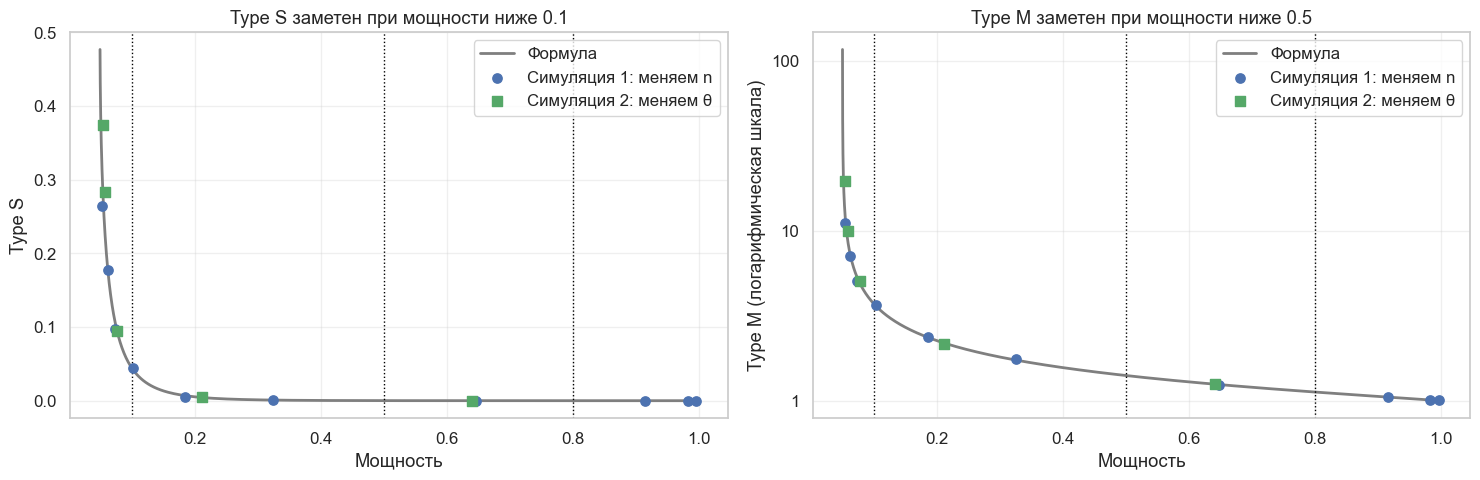

In [8]:
lambdas = np.geomspace(0.02, 5, 400)
theory = retrodesign(lambdas, 1.0)
points = pd.concat([df_sim1[["power", "type_s", "type_m"]].assign(source='Симуляция 1: меняем n'),
                    df_sim2.loc[df_sim2["Истинный эффект"] > 0, ["power", "type_s", "type_m"]].assign(source='Симуляция 2: меняем θ')])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, key, title in ((axes[0], 'type_s', 'Type S заметен при мощности ниже 0.1'), (axes[1], 'type_m', 'Type M заметен при мощности ниже 0.5')):
    ax.plot(theory['power'], theory[key], color=GRAY, linewidth=2, label='Формула')
    for (source, part), marker, color in zip(points.groupby('source'), 'os', (BLUE, GREEN)):
        ax.scatter(part['power'], part[key], marker=marker, color=color, s=45, zorder=3, label=source)
    for level in (0.1, 0.5, 0.8):
        ax.axvline(level, color='black', linestyle=':', linewidth=1)
    ax.set_xlabel('Мощность')
    ax.set_title(title)
    ax.legend()
axes[0].set_ylabel('Type S')
axes[1].set_ylabel('Type M (логарифмическая шкала)')
axes[1].set_yscale('log')
axes[1].yaxis.set_major_formatter(plt.ScalarFormatter())
plt.tight_layout()
plt.show()


Все точки легли на одну кривую. Значит, зная только мощность для правдоподобного эффекта, можно сразу назвать Type S и Type M. Это ровно рисунок 2 из статьи Gelman & Carlin: проблемы с завышением начинаются при мощности ниже 0.5, а со знаком — ниже 0.1.


### Симуляция №3: фильтр значимости и проклятие победителя

**Фильтр значимости (significance filter).** В каждом повторении эксперимента оценка $\hat{\theta}$ случайно колеблется вокруг истинного $\theta$, поэтому распределение всех оценок центрировано около истины. Но если оставить только результаты, прошедшие порог значимости, мы отбираем **экстремальные хвосты**. Этот отбор и создаёт завышение.

**Проклятие победителя (winner's curse).** Термин пришёл из аукционов: победитель часто побеждает потому, что сильнее всех переоценил лот и переплатил. В A/B-тестах логика похожая: значимыми чаще оказываются эксперименты, где наблюдённый эффект случайно оказался особенно большим. **Мы видим не типичный эффект, а эффект, прошедший отбор в сторону экстремальности.**

Возьмём слабый дизайн: $n = 5\,000$ на группу, истинный uplift +0.2 п.п.


Истинный эффект                            0.00200
Средняя оценка по всем симуляциям          0.00199
Средняя оценка среди значимых              0.00933
Средний модуль оценки среди значимых       0.01424
Минимальный модуль значимой оценки         0.01160
Мощность                                   0.06264
Type S                                     0.17656
Type M                                     7.11903
Значимых результатов                    3132.00000


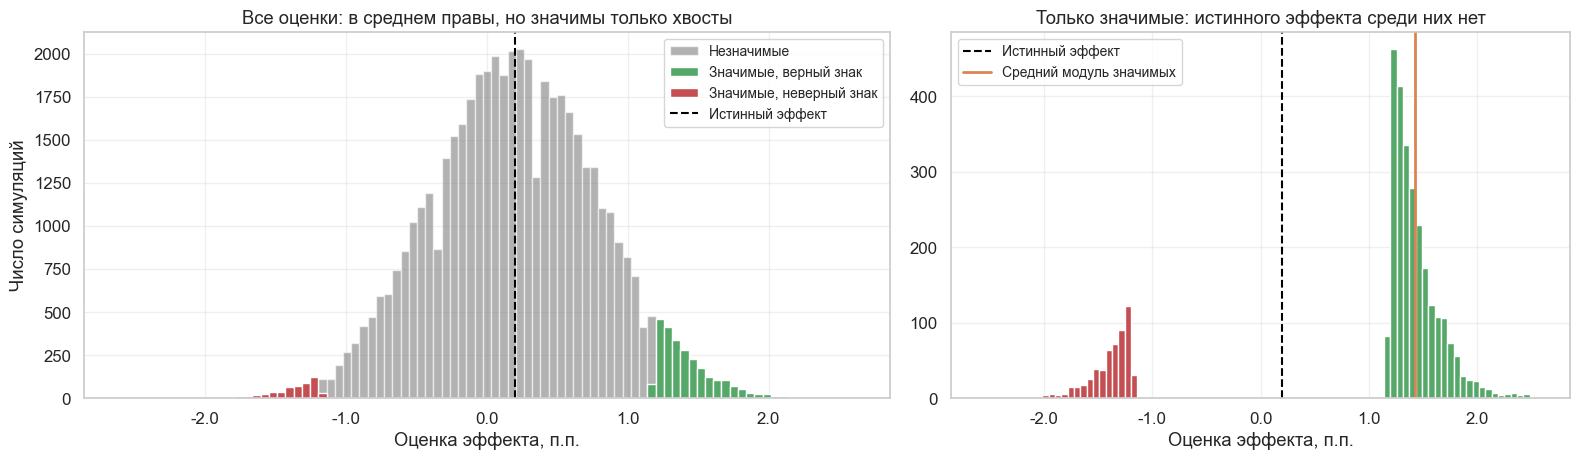

In [9]:
n_per_group = 5_000
sim3 = simulate_ab_binary(p_control, p_test, n_per_group, BASE_CONFIG["n_sim_hist"], alpha,
                          seed=BASE_CONFIG["base_seed"] + 3000)
significant_effects = sim3["effect_hat"][sim3["significant"]]
threshold = np.abs(significant_effects).min()

print(pd.Series({
    'Истинный эффект': sim3["true_effect"],
    'Средняя оценка по всем симуляциям': sim3["effect_hat"].mean(),
    'Средняя оценка среди значимых': significant_effects.mean(),
    'Средний модуль оценки среди значимых': np.abs(significant_effects).mean(),
    'Минимальный модуль значимой оценки': threshold,
    'Мощность': sim3["power"],
    'Type S': sim3["type_s"],
    'Type M': sim3["type_m"],
    'Значимых результатов': sim3["significant_count"],
}).round(5).to_string())

bins = np.linspace(-0.026, 0.026, 90)
wrong = significant_effects[significant_effects < 0]
right = significant_effects[significant_effects > 0]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={'width_ratios': [1.3, 1]})
axes[0].hist(sim3["effect_hat"][~sim3["significant"]], bins=bins, color=GRAY, alpha=0.6, label='Незначимые')
axes[0].hist(right, bins=bins, color=GREEN, label='Значимые, верный знак')
axes[0].hist(wrong, bins=bins, color=RED, label='Значимые, неверный знак')
axes[0].axvline(sim3["true_effect"], linestyle='--', color='black', label='Истинный эффект')
axes[0].set_title('Все оценки: в среднем правы, но значимы только хвосты')
axes[0].set_xlabel('Оценка эффекта, п.п.')
axes[0].set_ylabel('Число симуляций')
axes[0].legend(fontsize=10)

axes[1].hist(right, bins=bins, color=GREEN)
axes[1].hist(wrong, bins=bins, color=RED)
axes[1].axvline(sim3["true_effect"], linestyle='--', color='black', label='Истинный эффект')
axes[1].axvline(np.abs(significant_effects).mean(), color=ORANGE, linewidth=2, label='Средний модуль значимых')
axes[1].set_title('Только значимые: истинного эффекта среди них нет')
axes[1].set_xlabel('Оценка эффекта, п.п.')
axes[1].legend(fontsize=10)
for ax in axes:
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x * 100:.1f}'))
plt.tight_layout()
plt.show()


**Оценка сама по себе несмещена.** Среднее по всем $50\,000$ повторениям равно 0.00199 и практически совпадает с истинным $\theta = 0.002$. Проблема не в том, что метод некорректен.

**Смещение создаёт фильтр значимости.** Значимый результат дали только 3 132 из $50\,000$ повторений, это мощность около 6%. В этом дизайне значимых оценок меньше 0.0116 по модулю просто не бывает: это почти в 6 раз больше истинного эффекта. Поэтому на правом графике у линии истинного эффекта пусто.

Средний модуль значимой оценки равен 0.0142, это и есть Type M, равный 7.1. Среднее значимых оценок с учётом знака меньше (0.0093), потому что положительные и отрицательные оценки частично компенсируют друг друга. Но ни одна реальная команда не усредняет так свои результаты: она видит один тест и один большой uplift. Красный хвост — это Type S: 18% значимых результатов имеют неверный знак.

**Практический вывод.** Если истинный эффект около +0.2 п.п., а тест с такой выборкой дал значимый uplift от 1.2 п.п. и выше, то это в основном шум, усиливший сигнал. Статистическая значимость в слабом эксперименте — не конец анализа, а повод спросить: **«Не завышена ли оценка фильтром значимости?»**


## 5. Как это использовать в реальном A/B-тесте

Команда хочет протестировать новую фичу. Исторически подобные изменения давали uplift порядка $0.1 \text{–} 0.3 \text{ п.п.}$

Обычно команда задаёт $\alpha = 0.05$, выбирает мощность 80% и считает размер выборки под MDE ([лекция 1.05](<../05. Подбор уровня значимости и размера выборки теста/lecture.ipynb>)). Но важная деталь: **80% мощности — это мощность при эффекте, равном MDE.** Gelman и Carlin отдельно предупреждают, что минимальный эффект, который бизнесу интересен, часто больше правдоподобного. Посмотрим, что получает тест, рассчитанный на MDE, если истинный эффект оказался меньше:


In [10]:
se_at_mde = (stats.norm.ppf(0.975) + stats.norm.ppf(0.8)) ** -1  # в единицах MDE: при θ = MDE мощность равна 80%
shares = np.array([1.0, 0.75, 0.5, 1 / 3, 0.25])
design = retrodesign(shares, se_at_mde)

print(pd.DataFrame({
    'Истинный эффект / MDE': shares.round(2),
    'Мощность': design['power'].round(3),
    'Type S': design['type_s'].round(4),
    'Type M': design['type_m'].round(2),
}).to_string(index=False))


 Истинный эффект / MDE  Мощность  Type S  Type M
                  1.00     0.800  0.0000    1.12
                  0.75     0.556  0.0000    1.34
                  0.50     0.288  0.0013    1.85
                  0.33     0.154  0.0123    2.65
                  0.25     0.108  0.0362    3.47


Если MDE завышен вдвое, реальная мощность равна 29%, а значимые результаты преувеличивают эффект почти вдвое. Именно поэтому MDE нужно сравнивать с историей похожих тестов, а не только с тем, какой эффект окупит разработку.

Теперь посмотрим на эту же ситуацию с разными выборками, если реальный uplift равен +0.2 п.п.:


In [11]:
business_scenarios = {
    "Маленькая выборка": 3_000,
    "Средняя выборка": 15_000,
    "Большая выборка": 80_000,
    "Расчёт на мощность 80%": required_n(p_control, p_test, alpha),
}

rows = []
for scenario_name, n in business_scenarios.items():
    design = retrodesign(p_test - p_control, se_of_difference(p_control, p_test, n), alpha)
    rows.append({
        "Сценарий": scenario_name,
        "n на группу": n,
        "Мощность": design["power"],
        "Type S": design["type_s"],
        "Type M": design["type_m"],
        "Типичный значимый uplift, п.п.": design["type_m"] * (p_test - p_control) * 100,
    })

df_business = pd.DataFrame(rows)
print(df_business.round(3).to_string(index=False))


              Сценарий  n на группу  Мощность  Type S  Type M  Типичный значимый uplift, п.п.
     Маленькая выборка         3000     0.058   0.231   9.165                           1.833
       Средняя выборка        15000     0.089   0.063   4.189                           0.838
       Большая выборка        80000     0.264   0.002   1.933                           0.387
Расчёт на мощность 80%       356332     0.800   0.000   1.125                           0.225


Последняя колонка показывает, какой uplift увидит команда в типичном значимом результате. На малой выборке это около 1.8 п.п. при истинных 0.2 п.п. Если подставить такую оценку в прогноз выручки, он окажется завышен в 9 раз. Даже большая выборка в 80 000 на группу при мощности 0.26 завышает эффект почти вдвое. Только расчётная выборка даёт оценку, которой можно доверять.

Таким образом, хороший вывод по A/B-тесту отвечает на пять вопросов:

1. Какой наблюдённый эффект?
2. Значим ли он статистически?
3. Какова мощность теста для правдоподобного эффекта такого масштаба?
4. Каков риск Type S?
5. Насколько велик Type M, то есть завышение среди значимых результатов?

Только после этого решение «катить или не катить» становится действительно обоснованным.


## 6. Примеры из статьи Gelman & Carlin

Авторы иллюстрируют Design Analysis на двух опубликованных исследованиях. Оба показывают одно: **статистическая значимость сама по себе не говорит о том, что результат надёжен**.

### Кейс 1. Привлекательность родителей и пол ребёнка (Kanazawa, 2007)

Исследователь проанализировал данные 2 972 респондентов. Среди первых детей родителей из категории «самые привлекательные» 56% составляли девочки, в остальных группах — 48%. Разница в 8 п.п. оказалась значимой ($p = 0.015$), откуда следует $SE = 3.3$ п.п.

Какой истинный эффект реалистичен? В демографической литературе вариация доли рождений девочек обычно составляет от менее 0.3 до примерно 2 п.п., а более сильные сдвиги возникают только в условиях голода и бедности. Учитывая шумность оценки привлекательности, авторы ожидают эффект заметно меньше 1 п.п. и рассматривают три сценария: 0.1, 0.3 и 1.0 п.п.

### Кейс 2. Менструальный цикл и политические предпочтения (Durante et al., 2013)

Исследование сообщало о разнице в 17 п.п. в предпочтениях при голосовании у женщин в разных фазах цикла ($p = 0.035$), откуда $SE = 8.1$ п.п. Стандартная ошибка здесь примерно **в 4 раза** превышает правдоподобный эффект.

Авторы опираются на стабильность политических предпочтений: поддержка Обамы за всю кампанию 2012 года колебалась лишь в пределах 7 п.п. Поэтому 2 п.п. они считают верхней границей правдоподобного.

### Воспроизведение расчётов

Посчитаем оба кейса по формулам из раздела 2.4 и сравним со статьёй. Сценарии 5 п.п. и 17 п.п. в кейсе 2 добавлены для сравнения, в статье их нет.


In [12]:
paper_cases = [
    ('Кейс 1, θ = 0.1 п.п.', 0.1, 3.3, '5.0%, 46%, 77'),
    ('Кейс 1, θ = 0.3 п.п.', 0.3, 3.3, 'н/д, ~40%, 25'),
    ('Кейс 1, θ = 1.0 п.п.', 1.0, 3.3, '6.0%, 19%, 8'),
    ('Кейс 2, θ = 2 п.п.', 2.0, 8.1, '6%, 24%, 9.7'),
    ('Кейс 2, θ = 5 п.п.', 5.0, 8.1, 'нет в статье'),
    ('Кейс 2, θ = 17 п.п. (наблюдённый)', 17.0, 8.1, 'нет в статье'),
]

rows = []
for label, effect, se, paper in paper_cases:
    design = retrodesign(effect, se)
    rows.append({
        'Сценарий': label,
        'SE, п.п.': se,
        'Значимо, верный знак': design['p_right'],
        'Значимо, неверный знак': design['p_wrong'],
        'Мощность': design['power'],
        'Type S': design['type_s'],
        'Type M': design['type_m'],
        'Статья: мощность, S, M': paper,
    })

print(pd.DataFrame(rows).round(3).to_string(index=False))


                         Сценарий  SE, п.п.  Значимо, верный знак  Значимо, неверный знак  Мощность  Type S  Type M Статья: мощность, S, M
             Кейс 1, θ = 0.1 п.п.       3.3                 0.027                   0.023     0.050   0.465  77.157          5.0%, 46%, 77
             Кейс 1, θ = 0.3 п.п.       3.3                 0.031                   0.020     0.051   0.395  25.743          н/д, ~40%, 25
             Кейс 1, θ = 1.0 п.п.       3.3                 0.049                   0.012     0.061   0.195   7.796           6.0%, 19%, 8
               Кейс 2, θ = 2 п.п.       8.1                 0.043                   0.014     0.057   0.240   9.537           6%, 24%, 9.7
               Кейс 2, θ = 5 п.п.       8.1                 0.090                   0.005     0.095   0.053   3.913           нет в статье
Кейс 2, θ = 17 п.п. (наблюдённый)       8.1                 0.555                   0.000     0.555   0.000   1.339           нет в статье


Числа совпадают со статьёй. Небольшое отличие Type M в кейсе 2 (9.5 против 9.7) объясняется тем, что авторы считали его симуляцией.

Обратите внимание на первую строку. Вероятность значимого результата в верную сторону равна 2.7%, в неверную — 2.3%, а мощность — их сумма, 5%: по сути, чистый уровень значимости. Когда мощность равна $\alpha$, значимый результат почти ничего не говорит о знаке.

Последняя строка показывает ловушку из раздела 3.2: если подставить наблюдённые 17 п.п., дизайн выглядит приемлемо — мощность 55%, Type M 1.3. При правдоподобных 2 п.п. картина совсем другая.

### Что показывают оба кейса

Авторы получили значимые результаты с большими наблюдёнными эффектами, 8 и 17 п.п. Но Design Analysis показывает: при правдоподобных истинных эффектах оба дизайна были слишком слабыми.

Это не означает, что исходные результаты заведомо неверны. Это означает, что **такие дизайны не позволяли отличить реальный эффект от шума** ни по знаку, ни по масштабу.

Для A/B-тестов вывод тот же: если дизайн слаб относительно правдоподобного эффекта, значимый результат — не конец анализа, а повод задать дополнительные вопросы.


## 7. Что делать на практике

Design Analysis показывает проблему, но не решает её. Сами Gelman и Carlin рекомендуют для слабых данных предварительно зарегистрированную репликацию либо честное указание ограничений через design-расчёт. Остальные подходы ниже пришли из практики экспериментов.

### 7.1. Запланировать тест через Design Analysis

Лучше всего избежать проблемы заранее:

1. Оценить правдоподобный диапазон эффектов по истории похожих тестов или доменной экспертизе.
2. Для каждого сценария посчитать не только мощность, но и Type M и Type S.
3. Если Type M высок уже при реалистичном эффекте, честно признать: «Этот дизайн не позволяет надёжно оценить масштаб эффекта».
4. Увеличить выборку, снизить дисперсию ([лекция 1.04](<../04. Методы ускорения AB тестов/lecture.ipynb>)) или заранее скорректировать интерпретацию результата.

Ориентиры из той же универсальной кривой:


In [13]:
target_power = [0.06, 0.1, 0.17, 0.3, 0.5, 0.8, 0.9]
lambdas = np.linspace(0.01, 6, 6_000)
design = retrodesign(lambdas, 1.0)
idx = [np.argmin(np.abs(design['power'] - level)) for level in target_power]

print(pd.DataFrame({
    'Мощность': target_power,
    'θ / SE': lambdas[idx].round(2),
    'Type S': design['type_s'][idx].round(4),
    'Type M': design['type_m'][idx].round(2),
}).to_string(index=False))


 Мощность  θ / SE  Type S  Type M
     0.06    0.29  0.2014    8.02
     0.10    0.65  0.0450    3.71
     0.17    1.00  0.0091    2.49
     0.30    1.43  0.0011    1.81
     0.50    1.96  0.0001    1.41
     0.80    2.80  0.0000    1.12
     0.90    3.24  0.0000    1.06


* При мощности ниже 0.1 Type S становится заметным: знаку нельзя доверять.
* При мощности ниже 0.5 завышение быстро растёт. Уже при 0.3 оно составляет почти 2 раза.
* При мощности 0.8 Type M равен 1.12, а Type S практически нулевой, но только если мощность посчитана для реалистичного эффекта.

Резкого порога здесь нет: кривая плавная, и 80% — удобный ориентир, а не граница надёжности.


### 7.2. Не верить значимой оценке как есть: сжатие и репликация

**Репликация.** Если результат важен для бизнес-решения, лучший способ его проверить — **повторить эксперимент**. Завышение возникает из-за отбора по значимости, а новый запуск этому отбору не подвержен, поэтому его оценка не смещена.

Две детали. Выборку для репликации нельзя считать по завышенной оценке из первого теста, иначе вторая попытка окажется ещё слабее, чем кажется. А повторять тест на другом сегменте пользователей можно только с оговоркой, что эффект там может законно отличаться. Роль репликации может сыграть и контрольная группа, оставленная после раскатки (holdout).

**Байесовское сжатие (shrinkage).** Если у компании есть история A/B-тестов, значимую оценку можно притянуть к типичному эффекту. Если большинство фич дают 0–0.5 п.п., то оценка 1.5 п.п. скорее завышена. Для нормальных априорного распределения $\theta \sim N(\mu, \tau^2)$ и оценки $\hat{\theta} \sim N(\theta, SE^2)$ апостериорное среднее равно

$$
\hat{\theta}_{\text{сжат}} = \lambda \cdot \hat{\theta} + (1 - \lambda) \cdot \mu, \qquad \lambda = \frac{\tau^2}{\tau^2 + SE^2}
$$

Чем шумнее тест относительно разброса истинных эффектов, тем меньше вес данных. Подробнее о байесовском подходе — в [лекции 2.04](<../../../2. Квази-эксперименты/Теоретический блок/04. Байесовские AB тесты>).

Сравним оба подхода. Смоделируем $400\,000$ экспериментов компании: истинные эффекты разные, в среднем +0.1 п.п. с разбросом 0.1 п.п., $SE = 0.3$ п.п. Оставим только «победителей» — значимые тесты с положительным эффектом.


Победителей: 24 441 из 400 000
                          Средняя оценка, п.п.  Средний истинный эффект, п.п.  RMSE, п.п.
Наблюдённая оценка                       0.726                          0.163       0.581
Сжатая, верный prior                     0.163                          0.163       0.095
Сжатая, prior втрое шире                 0.413                          0.163       0.272
Независимая репликация                   0.165                          0.163       0.301


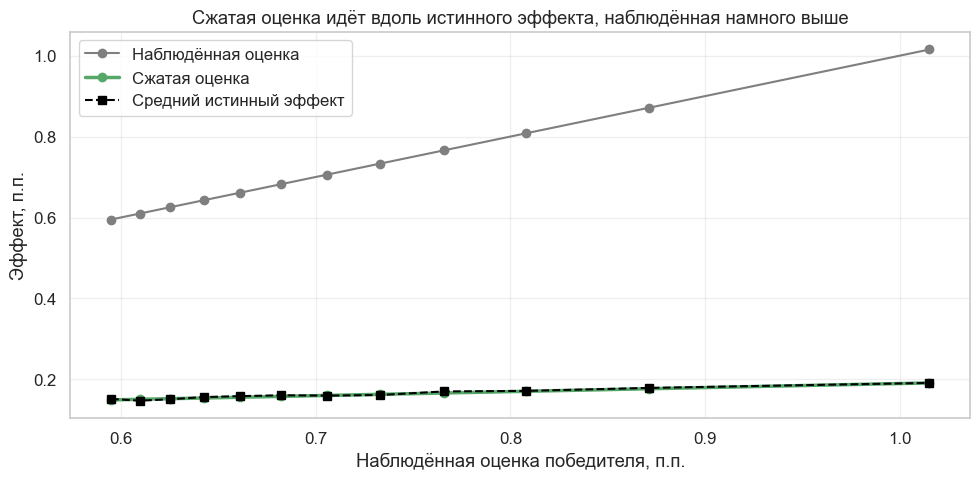

In [14]:
SHRINK_CONFIG = {
    "n_experiments": 400_000,
    "prior_mean": 0.001,  # история: в среднем +0.1 п.п.
    "prior_std": 0.001,  # разброс истинных эффектов между фичами
    "se": 0.003,  # примерно 20 000 пользователей на группу
}


def shrink(estimate: np.ndarray, se: float, prior_mean: float, prior_std: float) -> np.ndarray:
    """Сжимает оценку к среднему истории: апостериорное среднее нормальной модели."""
    weight = prior_std ** 2 / (prior_std ** 2 + se ** 2)
    return weight * estimate + (1 - weight) * prior_mean


rng = np.random.default_rng(BASE_CONFIG["base_seed"])
se = SHRINK_CONFIG["se"]
prior_mean, prior_std = SHRINK_CONFIG["prior_mean"], SHRINK_CONFIG["prior_std"]
true_effects_hist = rng.normal(prior_mean, prior_std, SHRINK_CONFIG["n_experiments"])
observed = true_effects_hist + rng.normal(0, se, SHRINK_CONFIG["n_experiments"])
replicated = true_effects_hist + rng.normal(0, se, SHRINK_CONFIG["n_experiments"])

winners = observed / se > stats.norm.ppf(0.975)  # значимые с положительным эффектом: их бы и раскатили
truth = true_effects_hist[winners]
estimators = {
    'Наблюдённая оценка': observed[winners],
    'Сжатая, верный prior': shrink(observed[winners], se, prior_mean, prior_std),
    'Сжатая, prior втрое шире': shrink(observed[winners], se, prior_mean, 3 * prior_std),
    'Независимая репликация': replicated[winners],
}
shrink_table = pd.DataFrame({
    name: {
        'Средняя оценка, п.п.': 100 * estimate.mean(),
        'Средний истинный эффект, п.п.': 100 * truth.mean(),
        'RMSE, п.п.': 100 * np.sqrt(np.mean((estimate - truth) ** 2)),
    } for name, estimate in estimators.items()
}).T
print(f'Победителей: {format_n_ru(winners.sum())} из {format_n_ru(winners.size)}')
print(shrink_table.round(3).to_string())

# Группируем победителей по наблюдённой оценке и смотрим, какой эффект у них на самом деле
bin_ids = pd.qcut(observed[winners], 12, labels=False)
calibration = pd.DataFrame({
    'observed': observed[winners],
    'truth': truth,
    'shrunk': estimators['Сжатая, верный prior'],
}).groupby(bin_ids).mean() * 100

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(calibration['observed'], calibration['observed'], 'o-', color=GRAY, label='Наблюдённая оценка')
ax.plot(calibration['observed'], calibration['shrunk'], 'o-', color=GREEN, linewidth=2.5, label='Сжатая оценка')
ax.plot(calibration['observed'], calibration['truth'], 's--', color='black', label='Средний истинный эффект')
ax.set_title('Сжатая оценка идёт вдоль истинного эффекта, наблюдённая намного выше')
ax.set_xlabel('Наблюдённая оценка победителя, п.п.')
ax.set_ylabel('Эффект, п.п.')
ax.legend()
plt.tight_layout()
plt.show()


Среди победителей наблюдённая оценка равна 0.73 п.п. при среднем истинном эффекте 0.16 п.п., то есть завышена примерно в 4.4 раза.

* **Сжатие с верным prior** убирает завышение и даёт наименьшую ошибку. Причём оно работает прямо среди значимых результатов, потому что байесовская оценка учитывает, откуда взялись эффекты.
* **Слишком широкий prior** лишь частично решает проблему. Качество сжатия зависит от того, насколько хорошо мы знаем разброс эффектов. $\tau^2$ нельзя оценивать по разбросу наблюдённых эффектов: в нём есть ещё и шум $SE^2$, а если в истории только значимые тесты, он завышен отбором.
* **Репликация** не смещена, но у одного запуска ошибка высока: $SE$ тот же. Она надёжна по среднему, а на отдельном тесте шумна.

**Попробуйте сами.** Поменяйте SE и разброс истории $\tau$: посмотрите, когда данные перевешивают prior.


In [15]:
def shrinkage_demo(estimate_pp: float = 1.5, se_pp: float = 0.5, prior_mean_pp: float = 0.2, prior_std_pp: float = 0.2) -> None:
    """Показывает, как априорное знание и данные дают сжатую оценку."""
    weight = prior_std_pp ** 2 / (prior_std_pp ** 2 + se_pp ** 2)
    posterior_mean = weight * estimate_pp + (1 - weight) * prior_mean_pp
    posterior_std = np.sqrt(weight) * se_pp
    grid = np.linspace(min(prior_mean_pp - 4 * prior_std_pp, estimate_pp - 4 * se_pp),
                       max(prior_mean_pp + 4 * prior_std_pp, estimate_pp + 4 * se_pp), 500)

    fig, ax = plt.subplots(figsize=(11, 4.5))
    ax.plot(grid, stats.norm.pdf(grid, prior_mean_pp, prior_std_pp), color=BLUE, label='История (prior)')
    ax.plot(grid, stats.norm.pdf(grid, estimate_pp, se_pp), color=GRAY, label='Данные теста')
    ax.plot(grid, stats.norm.pdf(grid, posterior_mean, posterior_std), color=GREEN, linewidth=2.5, label='Сжатая оценка')
    ax.axvline(posterior_mean, color=GREEN, linestyle='--')
    ax.set_title(f'Вес данных λ = {weight:.2f}: оценка {estimate_pp:.2f} п.п. сжимается до {posterior_mean:.2f} п.п.')
    ax.set_xlabel('Эффект, п.п.')
    ax.set_yticks([])
    ax.legend()
    plt.tight_layout()
    plt.show()


interact(shrinkage_demo,
         estimate_pp=FloatSlider(value=1.5, min=-3, max=3, step=0.1, description='Оценка, п.п.'),
         se_pp=FloatSlider(value=0.5, min=0.05, max=2, step=0.05, description='SE, п.п.'),
         prior_mean_pp=FloatSlider(value=0.2, min=-1, max=1, step=0.05, description='μ истории'),
         prior_std_pp=FloatSlider(value=0.2, min=0.05, max=2, step=0.05, description='τ истории'));


### 7.3. Чего делать не стоит

**Не нужно** после значимого результата подставлять наблюдённый эффект в расчёт мощности и радоваться высокому числу. Как мы видели, это то же p-value в другой шкале, и завышенная оценка лишь подтверждает сама себя.

Также не стоит останавливать тест, как только он стал значимым: подглядывание добавляет ещё один отбор по экстремальности ([лекция 2.01](<../../../2. Квази-эксперименты/Теоретический блок/01. Последовательное тестирование>)).


## 8. Выводы

1. **Мощность — важная, но не исчерпывающая характеристика эксперимента.** Она показывает вероятность обнаружить эффект, но не говорит, насколько можно доверять знаку и размеру значимого результата.
2. **Type S** показывает риск перепутать направление эффекта. Для A/B-тестов это особенно опасно: можно принять решение в неправильную сторону.
3. **Type M** показывает, насколько значимый результат преувеличивает реальный uplift. С практической точки зрения это одна из главных проблем слабых тестов: порог значимости сам задаёт минимальное завышение.
4. **Мощность, Type S и Type M зависят только от $|\theta| / SE$.** Поэтому мощность, посчитанная для правдоподобного эффекта, сразу даёт оба риска. Мощность, посчитанная для MDE, может быть оптимистичной, а наблюдаемая мощность бесполезна.
5. **Design Analysis** шире изолированного Power Analysis: он оценивает не только вероятность значимости, но и риски ошибочного знака и преувеличенного масштаба.
6. **Значимую оценку из слабого теста не стоит брать как есть:** её нужно сжимать к истории или проверять репликацией.
